##0 Descarga de las librerias que se usaran


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Carga e inspección de datos

In [ ]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

print(df.head())
print(df.tail())
df.info()
print(df.describe())
print(df.isnull().sum())

print("Resumen general del dataset")
print("Total de pacientes: {df.shape[0]}")
print("Edad promedio: {df['age'].mean():.2f} años")
print("Glucosa máxima: {df['avg_glucose_level'].max()}")
print("IMC promedio: {df['bmi'].mean():.2f}")

      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  
         id  gender   age  hypertension  heart_disease e

# 2. Limpieza y transformación de datos

In [ ]:
# La mediana permite conservar un valor representativo al completar los datos faltantes de BMI.
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

q1, q3 = np.percentile(df["avg_glucose_level"], [25, 75])
iqr = q3 - q1

lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

n_out = (
    (df["avg_glucose_level"] < lim_inf) |
    (df["avg_glucose_level"] > lim_sup)
).sum()

resultados_iqr = pd.DataFrame({
    "Indicador": ["Primer cuartil (Q1)", "Tercer cuartil (Q3)",
                  "Rango intercuartílico (IQR)", "Límite inferior",
                  "Límite superior", "Valores atípicos"],
    "Resultado": [
        round(q1, 2), round(q3, 2), round(iqr, 2),
        round(lim_inf, 2), round(lim_sup, 2), n_out
    ]
})

display(resultados_iqr)

df = pd.get_dummies(df, drop_first=True).drop(
    columns="id", errors="ignore"
)

,Indicador,Resultado
0,Primer cuartil (Q1),77.24
1,Tercer cuartil (Q3),114.09
2,Rango intercuartílico (IQR),36.84
3,Límite inferior,21.98
4,Límite superior,169.36
5,Valores atípicos,627.00


# 3. Visualización de datos

Gráfica 1.-Distribución de derrames

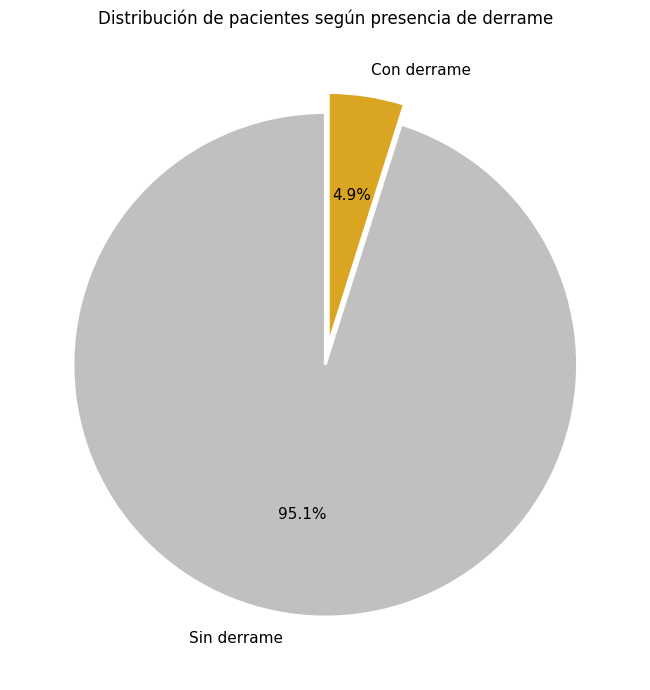

In [ ]:
# El conjunto de datos presenta un desbalance importante entre pacientes con y sin derrame.
plt.figure(figsize=(7, 7))

plt.pie(
    df["stroke"].value_counts(),
    labels=["Sin derrame", "Con derrame"],
    autopct="%1.1f%%",
    colors=["silver", "goldenrod"],
    startangle=90,
    explode=(0, 0.08),
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11}
)

plt.title("Distribución de pacientes según presencia de derrame", pad=18)
plt.tight_layout()
plt.show()

Gráfica 2.-Histogramas de edad y glucosa

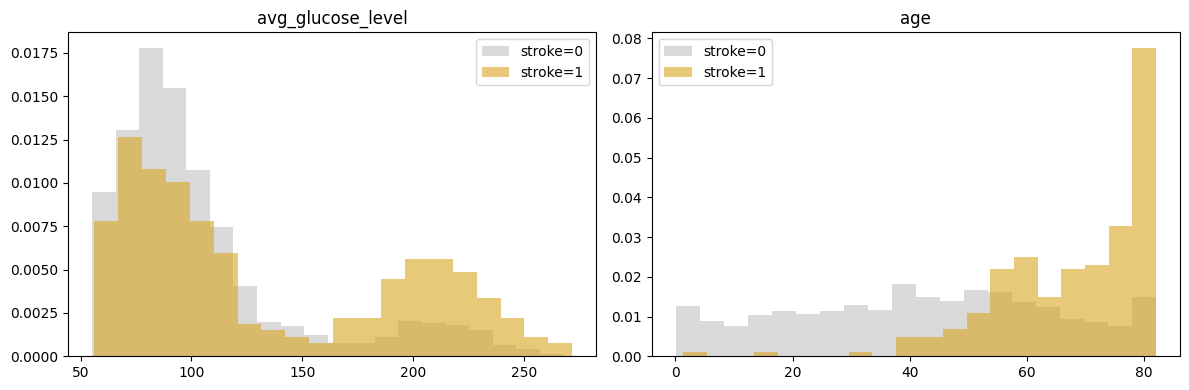

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axs, ["avg_glucose_level", "age"]):
    for s, c in [(0, "silver"), (1, "goldenrod")]:
        ax.hist(
            df[df["stroke"] == s][col],
            bins=20,
            alpha=0.6,
            density=True,
            color=c,
            label=f"stroke={s}"
        )

    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.show()

Dispersión de edad vs glucosa


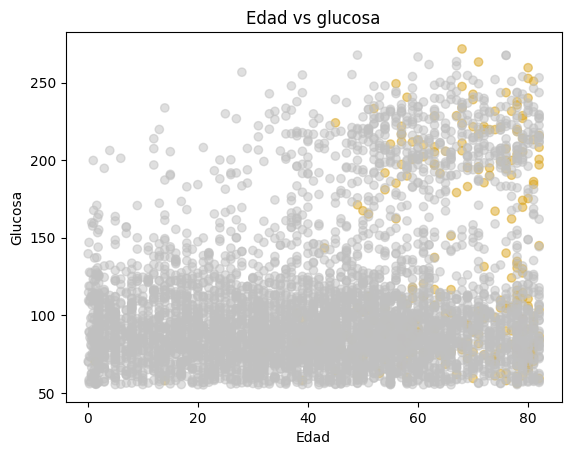

In [ ]:
from matplotlib.colors import ListedColormap

colores = ListedColormap(["silver", "goldenrod"])

plt.scatter(
    df["age"],
    df["avg_glucose_level"],
    c=df["stroke"],
    cmap=colores,
    alpha=0.5
)

plt.xlabel("Edad")
plt.ylabel("Glucosa")
plt.title("Edad vs glucosa")
plt.show()